# Project 4: Spotify — Pass 08

## Problem Definition


#### Business Problem

This project aims to predict the popularity of unreleased songs shortly following release, based on song data from Spotify's Top 200 Weekly (Global) charts from 2020 and 2021. Companies like Spotify may wish to understand and predict what types of tracks become hits and go viral, as these tracks can be promoted better and charge more for advertising.

#### Data Science Problem

Song popularity will be predicted using one of three different tree-based regression models: decision-tree, random forest, and xgboost.

Popularity is a continuous, numeric floating-point value. As such, this is a supervised regression problem, where the target of the prediction is the upcoming popularity of a prospective track release.

(Note: For passes 1-3, transactions data from Project 1 will be used. Similarly, for passes 4-6, housing data from Project 2 will be used. Passes 7-10 will utilize the spotify data particular to the above problem statement, with pass 10 having the most comprehensive use.)

In [38]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

import requests
from google.colab import userdata
import os

## Data Collection/Sources


### Authenticate to Hugging Face


In [39]:
# Retrieve the token from Colab's secret manager
os.environ["HF_TOKEN"] = userdata.get('hf_token')
_ = os.environ["HF_TOKEN"]
f"{_[:3]} ... {_[-4:]}"

'hf_ ... Tuux'

In [40]:
os.environ["HF_ACCOUNT"] = userdata.get('hf_account')
hf_account = os.environ["HF_ACCOUNT"]
hf_account


'timnickellddds'

In [41]:
hf_repo = "Data_Science-22"
os.environ["HF_REPO"] = hf_repo
hf_repo


'Data_Science-22'

In [42]:
# Log in automatically without an interactive prompt
! hf auth login --token $HF_TOKEN


The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `Colab` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


### Read parquet from Hugging Face


In [43]:
# Construct the base Hugging Face URL for your dataset files
hf_url = f"https://huggingface.co/datasets/{hf_account}/{hf_repo}/resolve/main/housing-numeric.parquet"
hf_url


'https://huggingface.co/datasets/timnickellddds/Data_Science-22/resolve/main/housing-numeric.parquet'

In [44]:
df_parquet = pd.read_parquet( hf_url )
df_parquet.shape


(2611, 27)

In [45]:
df_parquet.iloc[:,:5].info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2611 entries, 0 to 2610
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SalePrice     2611 non-null   int64  
 1   MS SubClass   2611 non-null   int64  
 2   Lot Frontage  2611 non-null   float64
 3   Lot Area      2611 non-null   int64  
 4   Overall Qual  2611 non-null   int64  
dtypes: float64(1), int64(4)
memory usage: 102.1 KB


## Data Cleaning


In [46]:
df = df_parquet

Basic Cleaning/Inspection

In [47]:
df.head()

,SalePrice,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,...,Bedroom AbvGr,Kitchen AbvGr,Fireplaces,Garage Cars,Wood Deck SF,Open Porch SF,Enclosed Porch,Screen Porch,Pool Area,Mo Sold
0,115400,20,62.0,14299,4,3,1964,1964,0.0,513.0,...,3,1,0,2.0,0,0,0,0,0,7
1,90000,90,72.0,10791,4,5,1967,1967,0.0,0.0,...,2,2,0,2.0,0,0,0,0,0,10
2,141000,50,50.0,9000,6,6,1937,1950,0.0,0.0,...,3,1,1,1.0,0,162,0,126,0,12
3,254000,60,68.0,7379,8,5,2000,2000,0.0,484.0,...,3,1,1,2.0,280,184,0,0,0,4
4,155000,70,60.0,7200,7,9,1936,2007,0.0,350.0,...,3,1,0,2.0,256,0,0,0,0,4


In [48]:
df.tail()

,SalePrice,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,...,Bedroom AbvGr,Kitchen AbvGr,Fireplaces,Garage Cars,Wood Deck SF,Open Porch SF,Enclosed Porch,Screen Porch,Pool Area,Mo Sold
2606,114500,50,52.0,6240,6,6,1934,1950,0.0,0.0,...,3,1,1,2.0,112,0,0,0,0,9
2607,162000,80,74.0,10778,7,6,1990,1991,0.0,460.0,...,1,1,0,2.0,114,36,0,0,0,7
2608,211500,120,61.0,3782,8,5,1981,1981,0.0,960.0,...,1,1,2,2.0,133,78,0,0,0,9
2609,165000,20,78.0,10140,6,5,1974,1974,174.0,0.0,...,3,1,1,2.0,0,0,0,0,0,8
2610,225000,60,41.0,12460,7,5,1999,2000,0.0,870.0,...,4,1,1,2.0,144,44,0,0,0,5


In [49]:
df.shape

(2611, 27)

In [50]:
df.size

70497

In [51]:
df.describe().transpose().head()

,count,mean,std,min,25%,50%,75%,max
SalePrice,2611.0,179525.874761,78191.558766,12789.0,129500.0,160000.0,212400.0,745000.0
MS SubClass,2611.0,57.449253,42.596350,20.0,20.0,50.0,70.0,190.0
Lot Frontage,2611.0,68.907315,21.262648,21.0,60.0,68.0,78.0,313.0
Lot Area,2611.0,10024.214477,6716.767206,1300.0,7420.0,9434.0,11506.0,164660.0
Overall Qual,2611.0,6.088472,1.410492,1.0,5.0,6.0,7.0,10.0


In [52]:
df.isnull().sum()*1000

,0
SalePrice,0
MS SubClass,0
Lot Frontage,0
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
Mas Vnr Area,0
BsmtFin SF 1,0


In [53]:
row_nulls_count = int(df.isnull().sum().sum())
row_nulls_count

0

In [54]:
print(f"Rows containing nulls: {row_nulls_count}")

Rows containing nulls: 0


In [55]:
# No data cleaning necessary for this pass:
# data cleaning performed in previous project.
# See Project 2 for reference.

## Exploratory Data Analysis


In [56]:
target_col = 'SalePrice'

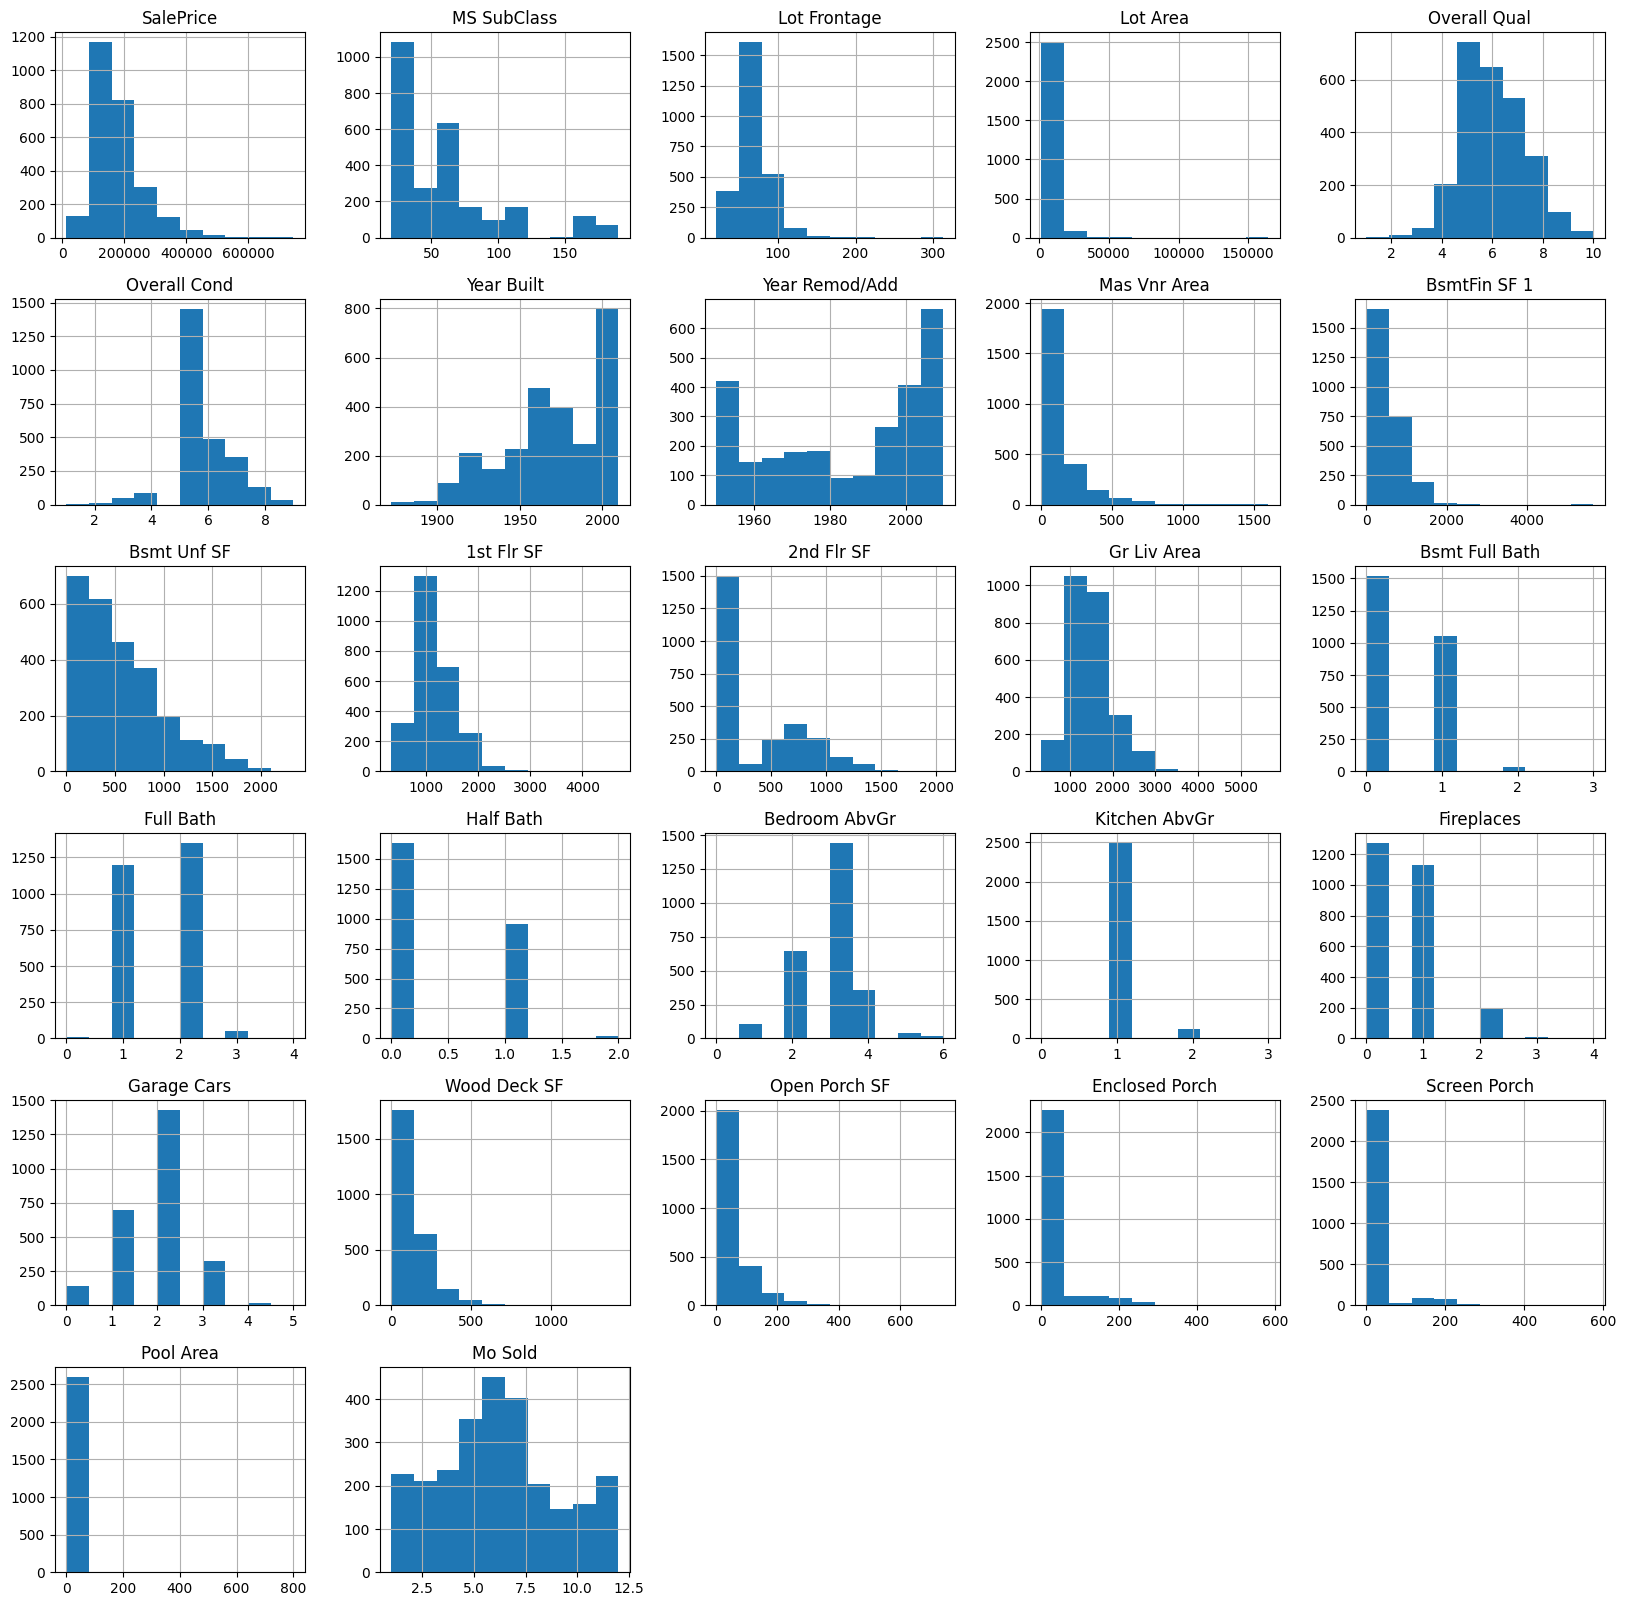

In [57]:
# Display a histogram
df.hist(figsize=(20, 20)) ;

Text(70.72222222222221, 0.5, 'Features')

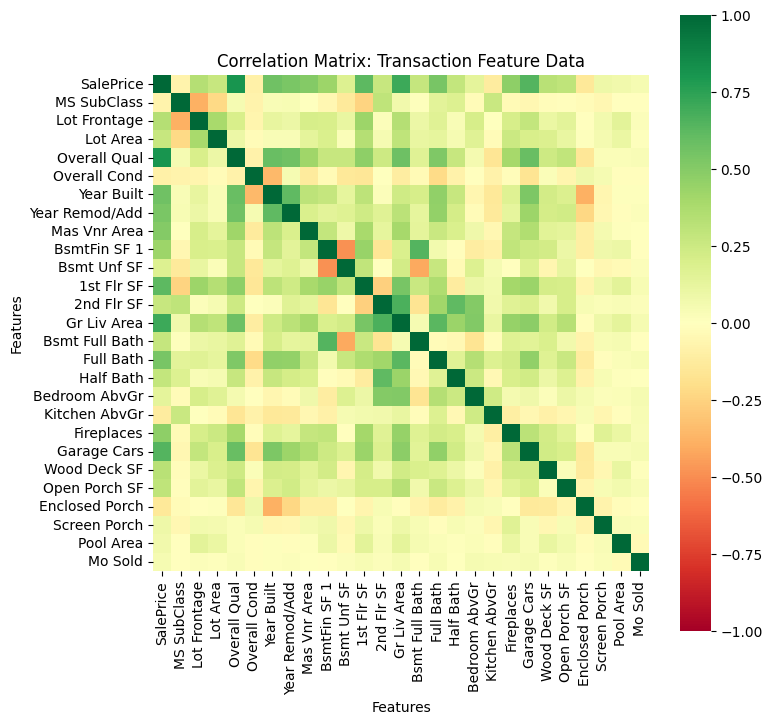

In [58]:
# column correlations
column_correlations = df.corr()

# Display correlation matrix
plt.figure(figsize = (8, 8))
sns.heatmap(
    column_correlations,
    annot = False,
    square = True,
    vmin = -1,
    vmax = 1,
    cmap = 'RdYlGn'
)
plt.title("Correlation Matrix: Transaction Feature Data")
plt.xlabel("Features")
plt.ylabel("Features")

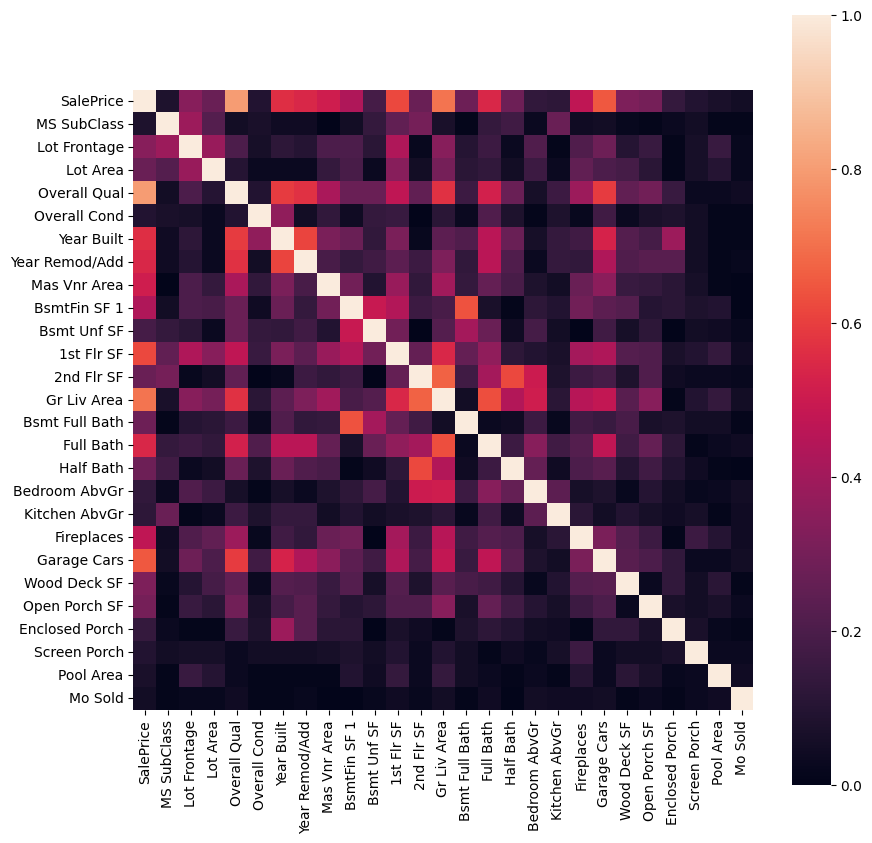

In [59]:
# Correlation plot — target and features
plt.figure(figsize=(10,10))
correlation_matrix = df.corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=False, vmin=0, vmax=1, square=True) ;


In [60]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False)

,SalePrice
SalePrice,1.00
Overall Qual,0.80
Gr Liv Area,0.71
Garage Cars,0.65
1st Flr SF,0.62
Year Built,0.56
Year Remod/Add,0.54
Full Bath,0.54
Mas Vnr Area,0.51
Fireplaces,0.47


<Axes: >

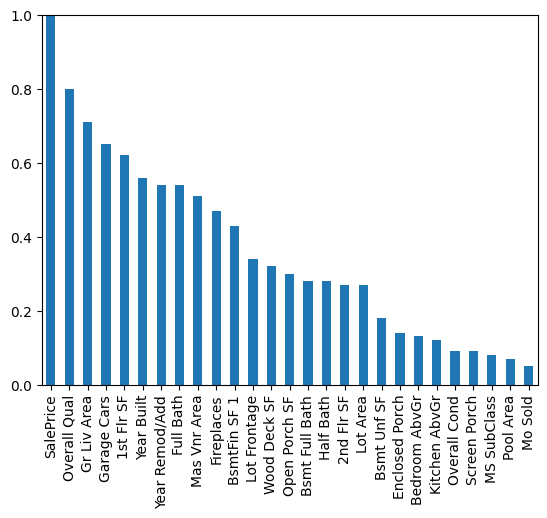

In [61]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False).plot( kind="bar", ylim = [0,1])

In [62]:
corrs = df.corr().round(2).unstack().abs()
corrs.reset_index()

,level_0,level_1,0
0,SalePrice,SalePrice,1.00
1,SalePrice,MS SubClass,0.08
2,SalePrice,Lot Frontage,0.34
3,SalePrice,Lot Area,0.27
4,SalePrice,Overall Qual,0.80
...,...,...,...
724,Mo Sold,Open Porch SF,0.03
725,Mo Sold,Enclosed Porch,0.01
726,Mo Sold,Screen Porch,0.03
727,Mo Sold,Pool Area,0.04


In [63]:
corrs = corrs[corrs < 1]
corrs.reset_index()

,level_0,level_1,0
0,SalePrice,MS SubClass,0.08
1,SalePrice,Lot Frontage,0.34
2,SalePrice,Lot Area,0.27
3,SalePrice,Overall Qual,0.80
4,SalePrice,Overall Cond,0.09
...,...,...,...
697,Mo Sold,Wood Deck SF,0.01
698,Mo Sold,Open Porch SF,0.03
699,Mo Sold,Enclosed Porch,0.01
700,Mo Sold,Screen Porch,0.03


In [64]:
corrs.sort_values(ascending = False).reset_index()

,level_0,level_1,0
0,Overall Qual,SalePrice,0.80
1,SalePrice,Overall Qual,0.80
2,SalePrice,Gr Liv Area,0.71
3,Gr Liv Area,SalePrice,0.71
4,Gr Liv Area,2nd Flr SF,0.67
...,...,...,...
697,Mo Sold,Mas Vnr Area,0.00
698,Mas Vnr Area,MS SubClass,0.00
699,Enclosed Porch,Bsmt Unf SF,0.00
700,Half Bath,Mo Sold,0.00


In [65]:
corrs.sort_values(ascending = False)[::2].reset_index()

,level_0,level_1,0
0,Overall Qual,SalePrice,0.80
1,SalePrice,Gr Liv Area,0.71
2,Gr Liv Area,2nd Flr SF,0.67
3,Garage Cars,SalePrice,0.65
4,BsmtFin SF 1,Bsmt Full Bath,0.64
...,...,...,...
346,Bsmt Unf SF,Enclosed Porch,0.00
347,2nd Flr SF,Overall Cond,0.00
348,Mo Sold,BsmtFin SF 1,0.00
349,Mas Vnr Area,MS SubClass,0.00


## Processing



In [66]:
target_col = 'SalePrice'

### Random Forest Regression

In [67]:
features = df.drop(target_col, axis = 1)
target = df[target_col]
X = features
y = target

In [68]:
# Multiple CV — loop count
n = 30

# Create array to hold results
rmses = np.zeros(n)
rmspes = np.zeros(n)

# Multiple CV loop
for i in range(n):

  # Train Test Split
  X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2 )

  # Create an empty model
  model = RandomForestRegressor(n_estimators = 10) # Arbitrarily choosing max_depth of 3

  # Train ( fit ) the model
  model.fit(X_train, y_train)

  # Make predictions using the model
  y_pred = model.predict(X_test)

  # Calculate the metric and save to array
  rmses[i]  = np.sqrt(np.mean(np.square(y_test - y_pred)))
  rmspes[i] = np.sqrt(np.mean(np.square((y_test - y_pred) / y_test))) * 100

In [69]:
# Calculate mean of results
mean_rmse = rmses.mean()
mean_rmse

np.float64(26905.071050742794)

In [70]:
# Calculate mean of results
mean_rmspe = rmspes.mean()
mean_rmspe

np.float64(19.753416686241604)

### How do we choose the number of trees?

In [79]:
loops_count = 30

num_trees = range(10,210,22)

rms_results  = np.zeros(len(num_trees))
rmsp_results = np.zeros(len(num_trees))
std_results  = np.zeros(len(num_trees))
stdp_results = np.zeros(len(num_trees))

numLoops = loops_count

for n, trees in enumerate(num_trees):
  rmses  = np.zeros(numLoops)
  rmspes = np.zeros(numLoops)

  for i in range(0,numLoops):
    # Train Test Split
    X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2 )

    # Create an empty model
    # model = RandomForestRegressor(n_estimators = trees)
    model = RandomForestRegressor(
      n_estimators = trees,
      max_depth = 15,
      min_samples_leaf = 5,
      min_samples_split = 20,
      n_jobs = -1
    )

    # Train ( fit ) the model
    model.fit(X_train, y_train)

    # Make predictions using the model
    y_pred = model.predict(X_test)

    # Calculate the metric and save to array
    rmses[i]  = np.sqrt(np.mean(np.square(y_test - y_pred)))
    rmspes[i] = np.sqrt(np.mean(np.square((y_test - y_pred) / y_test))) * 100

  print(trees,' trees finished.')
  rms_results[n] = rmses.mean()
  std_results[n] = rmses.std( ddof = 1 )
  rmsp_results[n] = rmspes.mean()
  stdp_results[n] = rmspes.std( ddof = 1 )

10  trees finished.
32  trees finished.
54  trees finished.
76  trees finished.
98  trees finished.
120  trees finished.
142  trees finished.
164  trees finished.
186  trees finished.
208  trees finished.


In [87]:
pd.DataFrame( zip( num_trees, rms_results, std_results ), columns = "treeno RMSE STDev".split() )


,treeno,RMSE,STDev
0,10,29021.242207,3190.962089
1,32,28733.261522,3638.138550
2,54,28011.509586,3159.425271
3,76,27522.458033,3723.644471
4,98,28907.891233,2286.689115
5,120,27019.325887,2352.475944
6,142,27920.077819,2661.475933
7,164,28203.745689,3023.619589
8,186,28769.717439,3035.806403
9,208,27605.890666,3168.110486


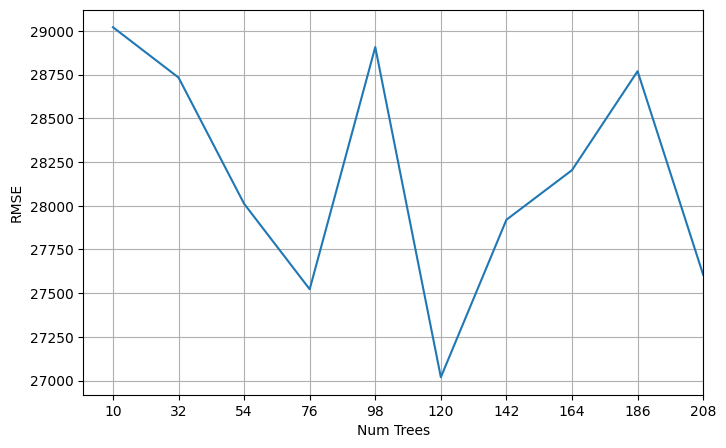

In [88]:
# Plot result
plt.figure(figsize = (8,5))
plt.plot(num_trees, rms_results)
plt.xlabel('Num Trees')
plt.ylabel('RMSE')
plt.xlim(0, 20.5)
plt.xticks(num_trees)
plt.grid()


In [89]:
pd.DataFrame( zip( num_trees, rmsp_results, stdp_results ), columns = "treeno RMSPE STDev".split() )


,treeno,RMSPE,STDev
0,10,21.705638,6.928369
1,32,21.788900,6.130593
2,54,22.382310,7.732666
3,76,20.208602,5.648839
4,98,21.534620,6.207290
5,120,20.642645,6.501174
6,142,19.538921,5.556695
7,164,21.802868,5.904197
8,186,22.329894,6.039375
9,208,20.644329,6.564886


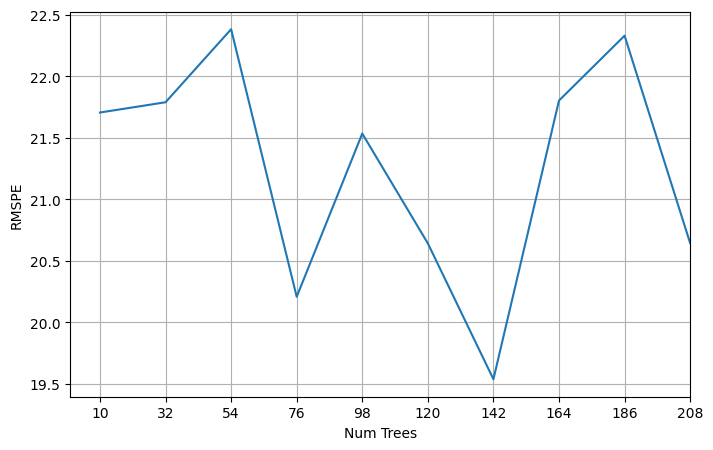

In [90]:
# Plot result
plt.figure(figsize = (8,5))
plt.plot(num_trees, rmsp_results)
plt.xlabel('Num Trees')
plt.ylabel('RMSPE')
plt.xlim(0, 20.5)
plt.xticks(num_trees)
plt.grid()


In [91]:
# Multiple CV — loop count
n = 30

trees = 142

# Create array to hold results
rmses = np.zeros(n)
rmspes = np.zeros(n)

# Multiple CV loop
for i in range(n):

  # Train Test Split
  X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2 )

  # Create an empty model
  model = RandomForestRegressor(n_estimators = trees)

  # Train ( fit ) the model
  model.fit(X_train, y_train)

  # Make predictions using the model
  y_pred = model.predict(X_test)

  # Calculate the metric and save to array
  rmses[i]  = np.sqrt(np.mean(np.square(y_test - y_pred)))
  rmspes[i] = np.sqrt(np.mean(np.square((y_test - y_pred) / y_test))) * 100

In [92]:
# Calculate mean of results
mean_rmse = rmses.mean()
mean_rmse

np.float64(26915.317777929657)

In [93]:
# Calculate mean of results
mean_rmspe = rmspes.mean()
mean_rmspe

np.float64(20.581259834041212)

## Data Visualization/Communication of Results


### Visualize the Random Forest

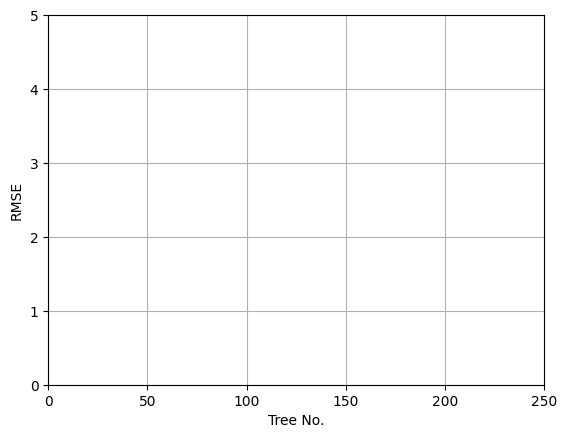

In [105]:
# plt.errorbar(num_trees, rmse_results, yerr=(std_results*2,std_results*2))
plt.errorbar(num_trees, rms_results, yerr=std_results)
plt.xlabel('Tree No.')
plt.ylabel('RMSE')
plt.ylim(0,5)
plt.xlim(0,250)
plt.grid()

In [106]:
import graphviz
from IPython.display import display
from sklearn import tree

In [107]:
len(model.estimators_)

142

In [108]:
# Display one tree from the random forest
display(
  graphviz.Source(
    tree.export_graphviz(
      model.estimators_[0],
      feature_names = X.columns,
    )
  )
)

### Find Important Predictors

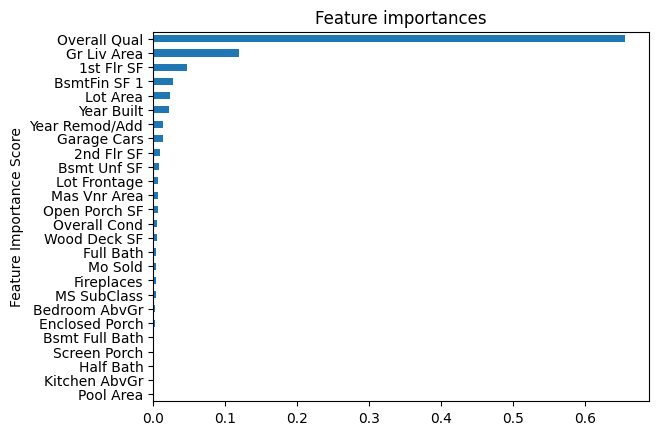

In [98]:
importances = model.feature_importances_
forest_importances = pd.Series( importances, index = X.columns )

plt.figure()
# forest_importances.plot.bar()
forest_importances.sort_values( ascending = True ).plot.barh()
plt.title("Feature importances")
plt.ylabel('Feature Importance Score') ;

In [99]:
( forest_importances.sort_values( ascending = False ) * 100 ).cumsum()

,0
Overall Qual,65.553248
Gr Liv Area,77.508414
1st Flr SF,82.225159
BsmtFin SF 1,84.991496
Lot Area,87.392789
Year Built,89.570443
Year Remod/Add,90.993132
Garage Cars,92.387345
2nd Flr SF,93.319628
Bsmt Unf SF,94.105848


### Visualize the Data

Text(0, 0.5, 'Frequency')

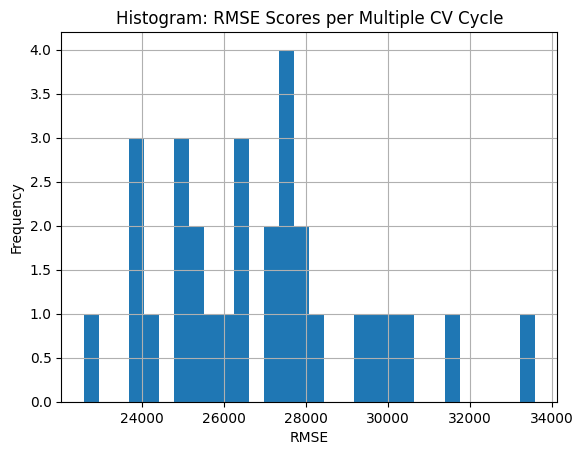

In [101]:
# Display a histogram of the results
pd.Series(rmses).hist(bins = 30)
plt.title("Histogram: RMSE Scores per Multiple CV Cycle")
plt.xlabel("RMSE")
plt.ylabel("Frequency")

Text(0, 0.5, 'Frequency')

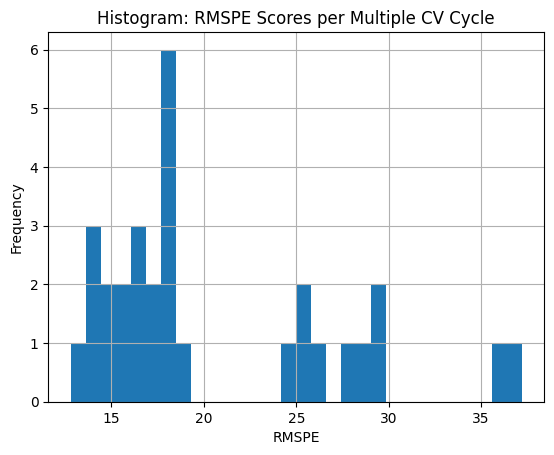

In [103]:
# Display a histogram of the results
pd.Series(rmspes).hist(bins = 30)
plt.title("Histogram: RMSPE Scores per Multiple CV Cycle")
plt.xlabel("RMSPE")
plt.ylabel("Frequency")

## Conclusions

- The best RMSPE was around 20.6%, and the best RMSE around 26000, which is much lower than in Project 2 (around 32000).
- Random Forest yields results with lower error, meaning it models the data better than a linear regression does.
- Random Forest also has the advantage of not needing to meet the requirements of linear regression (features are independent from the target, and are independent from one another (not collinear).